# F1 race pace: telemetry analysis and lap-time prediction

**Question:** given what is known at the start of a lap — tyre compound and age, team, how far into
the race we are — how well can we predict a race lap time at a track the model has never seen?

**Approach**
1. Explore detailed telemetry from one session (Monaco 2024 qualifying) to understand the data.
2. Build a dataset of every lap of the 2024 season (24 races, 26,661 laps) and clean it.
3. Compare models against simple baselines, using validation that holds out whole races.
4. Look at where the model fails and why.

Data: [FastF1](https://docs.fastf1.dev) (telemetry), [OpenF1](https://openf1.org) (laps, tyres, weather),
[Ergast / Jolpica](https://github.com/jolpica/jolpica-f1) (official qualifying results).

In [1]:
import sys
sys.path.append("../src")

import logging
import warnings
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.WARNING)
pd.set_option("display.precision", 3)
%matplotlib inline

from data_loader import load_season_race_laps, load_telemetry_sample
from feature_engineering import (FEATURE_SETS, TARGET, add_race_features, clean_race_laps,
                                 extract_lap_features, train_test_split_by_round)
from model_trainer import F1ModelTrainer
from visualizer import F1Visualizer

viz = F1Visualizer()

## 1. Telemetry: Monaco 2024 qualifying

Leclerc took pole ahead of Piastri and Sainz. The car sends speed, throttle, brake, RPM, gear and
GPS position several times per second.

In [2]:
telemetry, sectors = load_telemetry_sample(2024, "Monaco", "Q", ["LEC", "PIA", "SAI"])
pd.DataFrame([extract_lap_features(t) for t in telemetry.values()]).set_index("Driver").T

Driver,LEC,PIA,SAI
LapTime_s,70.270,70.424,70.518
speed_mean,166.700,169.781,168.716
speed_max,288.000,286.000,289.000
speed_min,46.000,47.000,44.000
full_throttle_pct,44.527,41.667,44.796
time_full_throttle_s,30.835,28.444,31.519
brake_events,15.000,11.000,12.000
time_braking_s,17.548,16.454,17.506
gear_changes,46.000,46.000,46.000
time_in_corners_pct,65.306,63.148,64.498


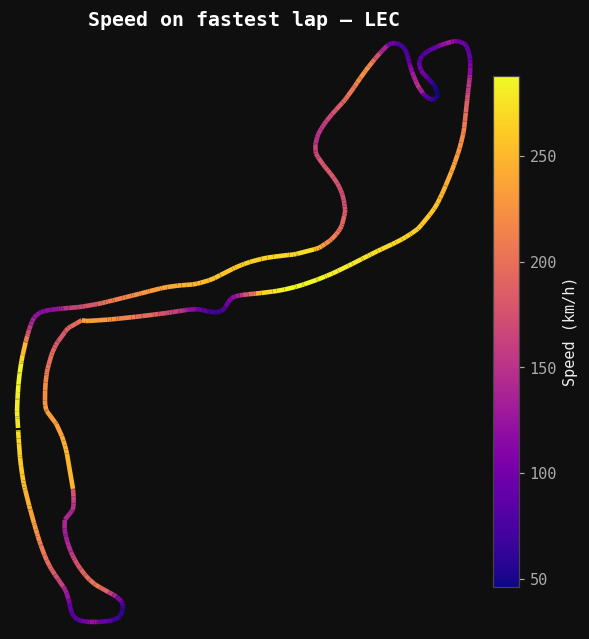

In [3]:
viz.plot_circuit_speed(telemetry["LEC"], "LEC");

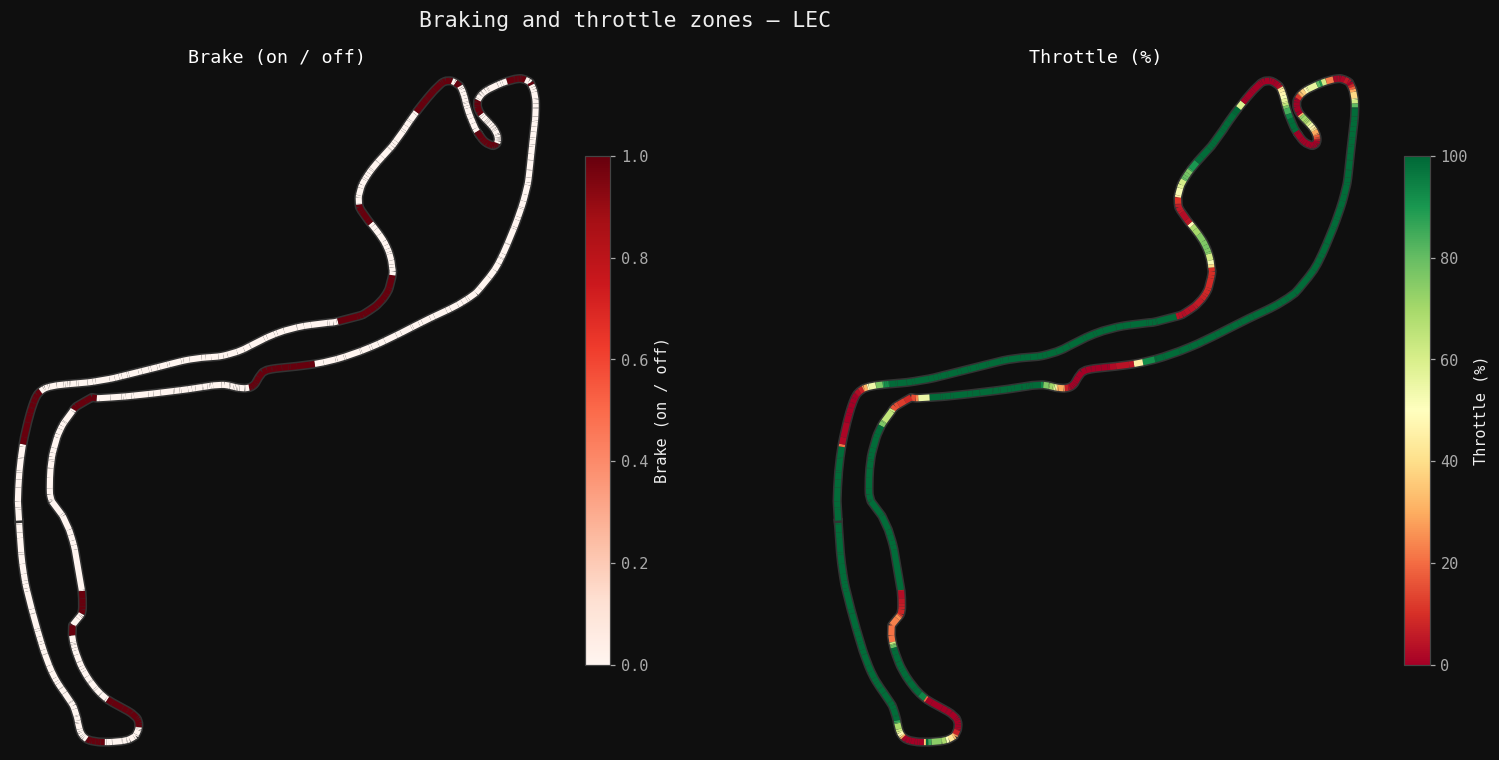

In [4]:
viz.plot_braking_acceleration_zones(telemetry["LEC"], "LEC");

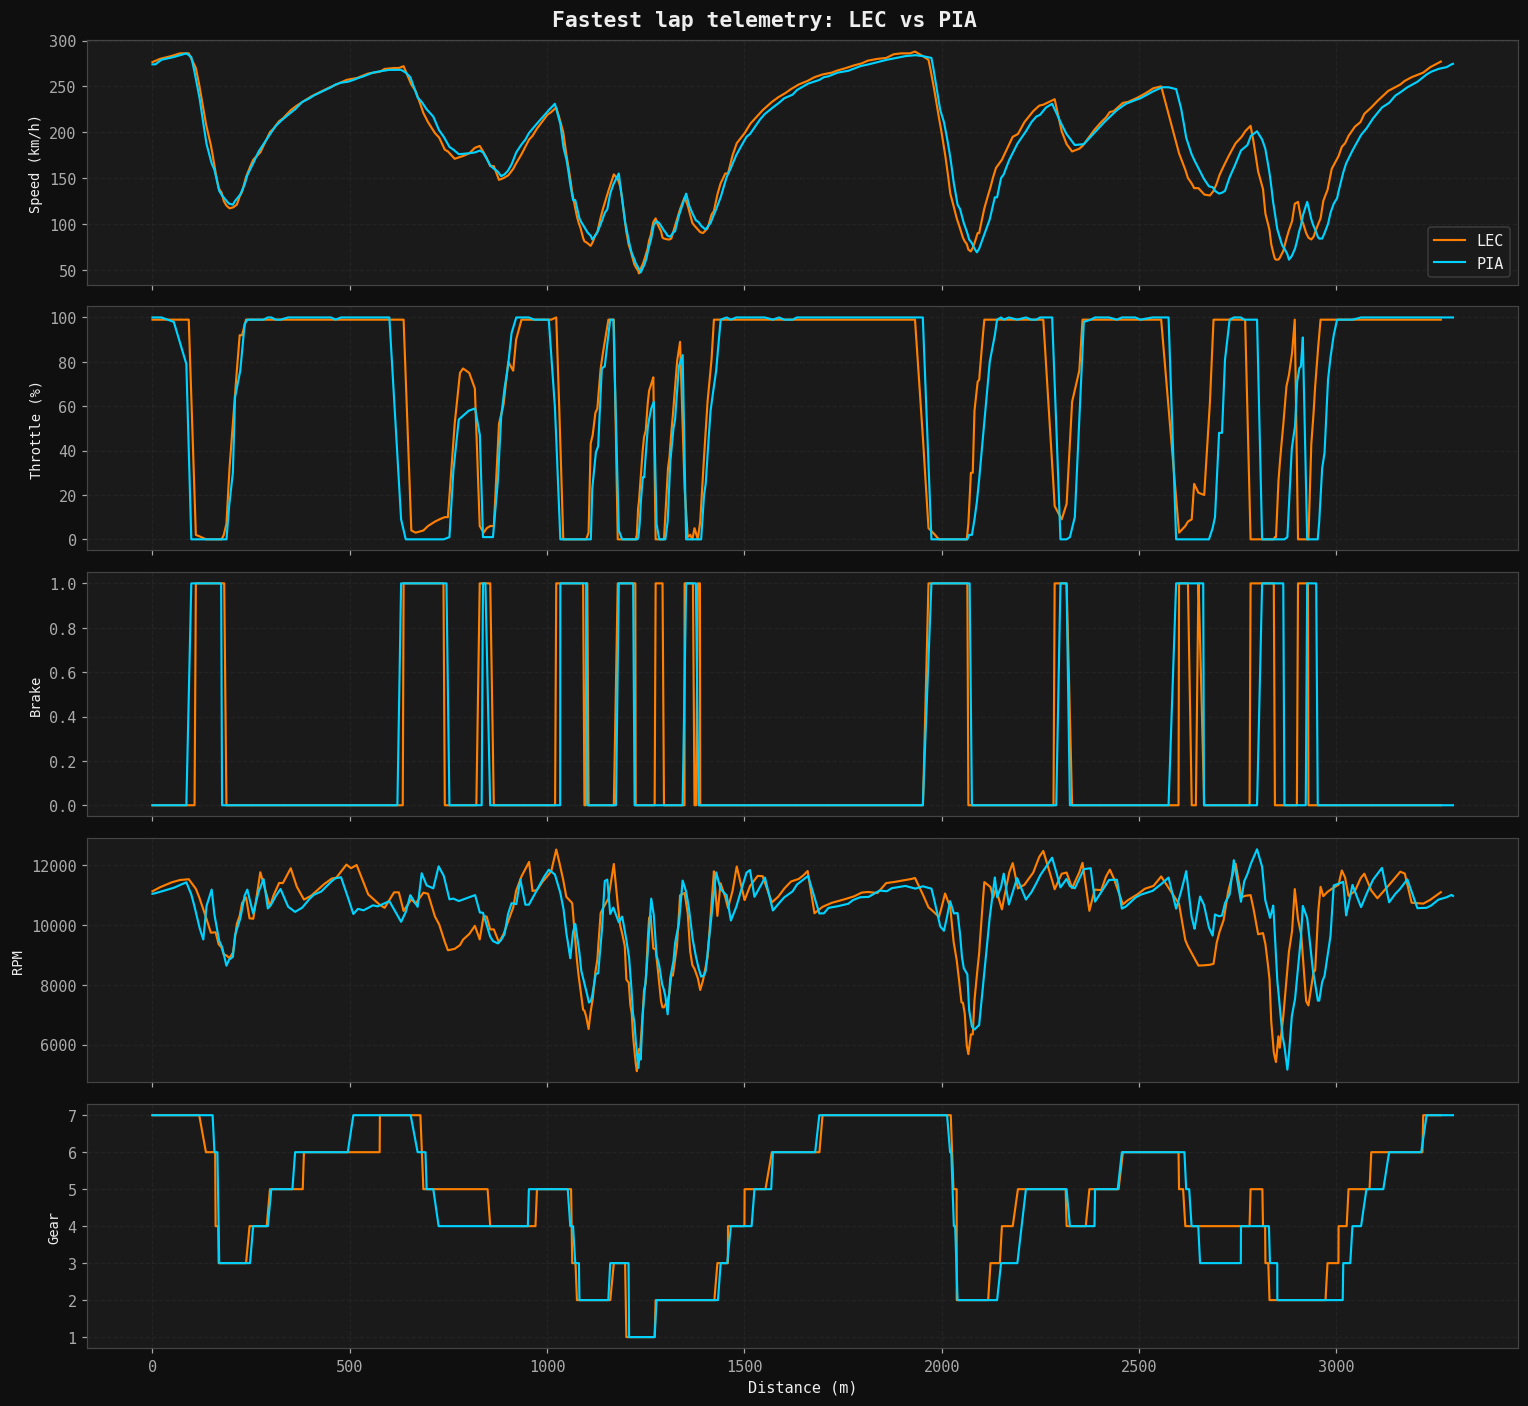

In [5]:
viz.plot_telemetry_comparison(telemetry["LEC"], telemetry["PIA"], "LEC", "PIA");

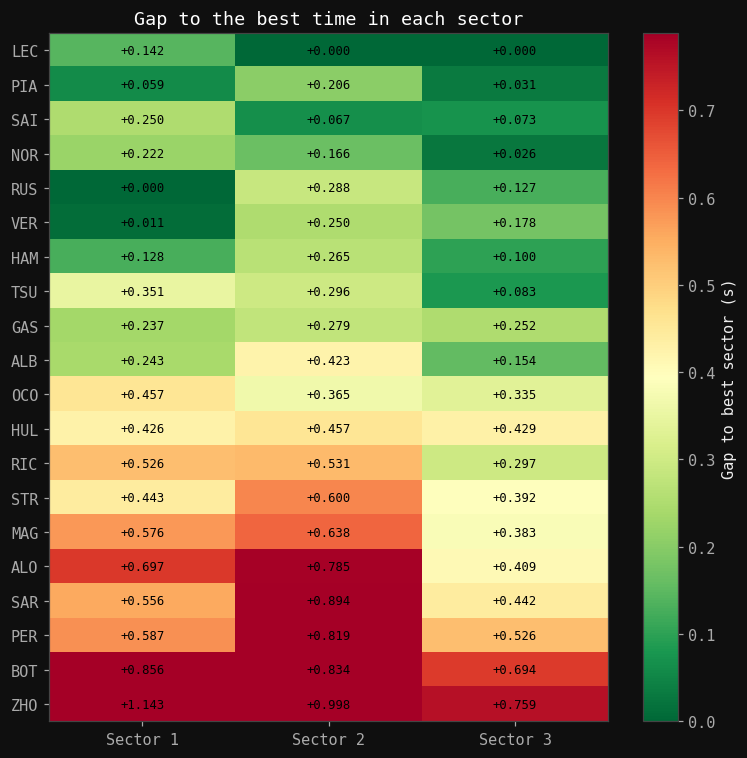

In [6]:
viz.plot_sector_analysis(sectors);

**Takeaways.** Monaco is slow and twisty: the car is below 200 km/h for about 65% of the lap and
flat out for less than half of it. Leclerc was fastest in sectors 2 and 3 but only 5th in
sector 1: his pole came from the twisty middle and final parts of the lap.

Telemetry is rich but exists for very few laps per driver. For a predictive model, the lap-level
data of a whole season is more useful.

## 2. Season dataset

One row per lap for every 2024 race: lap time, tyre compound and age, stint, team, weather at the
start of the lap, and the fastest qualifying lap of that weekend.

**Target: `pct_off_pole`** — how much slower the race lap is than pole, in %. Raw lap times
can't be compared across tracks (70 s in Monaco, 105 s in Spa); dividing by the pole time
removes most of that difference. The pole time is set *before* the race, so this doesn't leak
race information into the features.

**What is not used as a feature:** sector times (they add up to the lap time, so a model can
"predict" perfectly by adding them — the previous version of this project did exactly that and
scored R² = 1.0), and anything measured after the lap starts.

In [7]:
raw = load_season_race_laps(2024)
print(f"{len(raw):,} laps, {raw['round'].nunique()} races")
raw.head()

26,661 laps, 24 races


,driver_number,lap_number,date_start,lap_duration,is_pit_out_lap,stint_number,compound,tyre_age,is_pit_in_lap,name_acronym,team_name,track_temperature,air_temperature,humidity,rainfall,round,location,race_laps,pole_time_s,quali_wet_share
0,1,1,2024-03-02 15:03:42.341000+00:00,97.759,False,1,SOFT,3.0,False,VER,Red Bull Racing,23.8,18.3,49.0,0,1,Sakhir,57,89.165,0.0
1,31,1,2024-03-02 15:03:42.341000+00:00,107.083,False,1,SOFT,0.0,False,OCO,Alpine,23.8,18.3,49.0,0,1,Sakhir,57,89.165,0.0
2,24,1,2024-03-02 15:03:42.341000+00:00,105.213,False,1,SOFT,0.0,False,ZHO,Kick Sauber,23.8,18.3,49.0,0,1,Sakhir,57,89.165,0.0
3,20,1,2024-03-02 15:03:42.341000+00:00,104.851,False,1,SOFT,0.0,False,MAG,Haas F1 Team,23.8,18.3,49.0,0,1,Sakhir,57,89.165,0.0
4,18,1,2024-03-02 15:03:42.341000+00:00,110.537,False,1,SOFT,0.0,False,STR,Aston Martin,23.8,18.3,49.0,0,1,Sakhir,57,89.165,0.0


### Cleaning

Every rule and the number of laps it removes:

In [8]:
laps, cleaning_report = clean_race_laps(raw)
laps = add_race_features(laps)
cleaning_report

,rule,laps_removed,laps_left
0,missing lap time,34,26627
1,lap 1 (standing start),435,26192
2,pit out-lap,824,25368
3,pit in-lap,754,24614
4,wet qualifying (pole time not comparable),1797,22817
5,intermediate / wet tyres,976,21841
6,"> 20% off pole (safety car, incidents)",830,21011


Why these rules:
- **Lap 1, pit in-laps and out-laps** are slow for reasons unrelated to pace.
- **Wet qualifying** (Spa, São Paulo): the pole time was set on intermediate/wet tyres, so it
  isn't a fair reference. At Spa the race laps came out *faster* than pole. Wet sessions are
  detected from the share of wet-weather tyres used in qualifying, not hard-coded.
- **Intermediate / wet tyres in the race:** too few laps to learn from.
- **More than 20% off pole:** safety car and virtual safety car laps. Green-flag laps are almost all
  below 16%.

Result: 21,011 laps from 22 races.

### Train / test split

The data is split **by time**: rounds 1–18 for training and model selection, rounds 19–24 kept
aside until the very end. A random split would put laps from the same race (same track, same
conditions, same day) in both sets and make the model look better than it is.

In [9]:
FIRST_TEST_ROUND = 19
train, test = train_test_split_by_round(laps, FIRST_TEST_ROUND)
print(f"train: {len(train):,} laps from {train['round'].nunique()} races")
print(f"test:  {len(test):,} laps from {test['round'].nunique()} races: {', '.join(test['location'].unique())}")

train: 16,522 laps from 17 races
test:  4,489 laps from 5 races: Austin, Mexico City, Las Vegas, Lusail, Yas Island


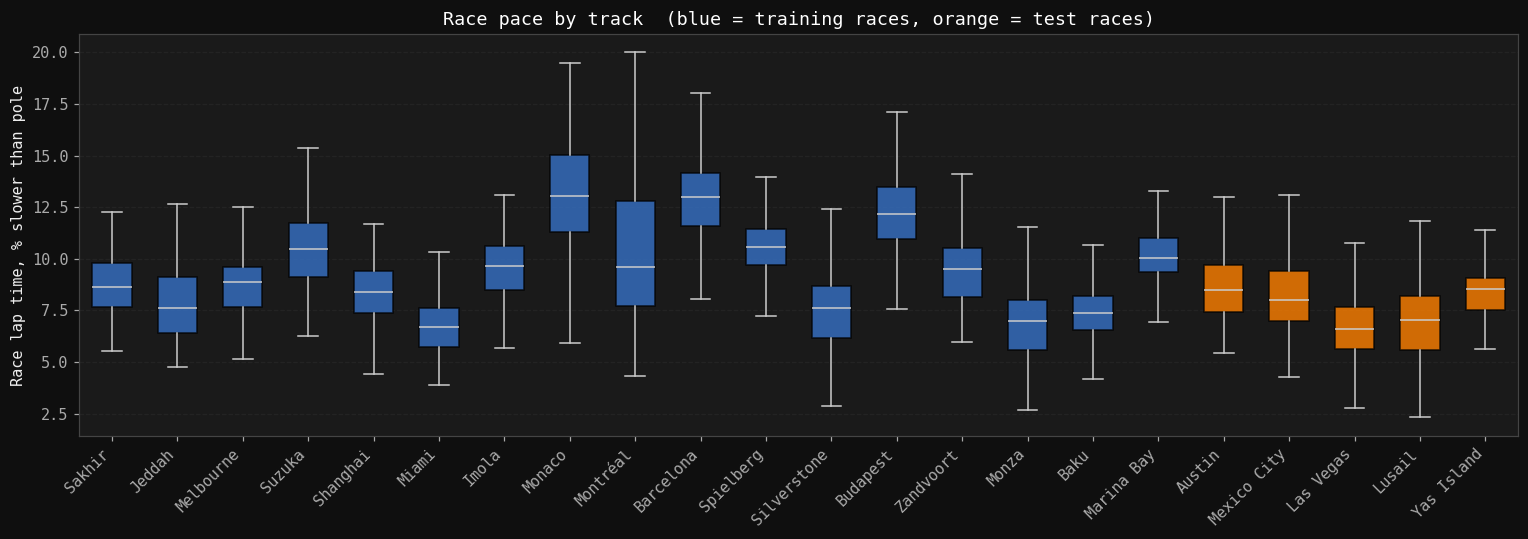

In [10]:
viz.plot_target_by_race(laps, TARGET, FIRST_TEST_ROUND);

Normalising by pole works only partly. The typical race lap ranges from about 7% off pole
(Miami, Monza, Las Vegas) to 13% (Monaco, Barcelona), depending on the track. For a track the
model hasn't seen, this difference can't be learned from these features. That limits what any
model can achieve here.

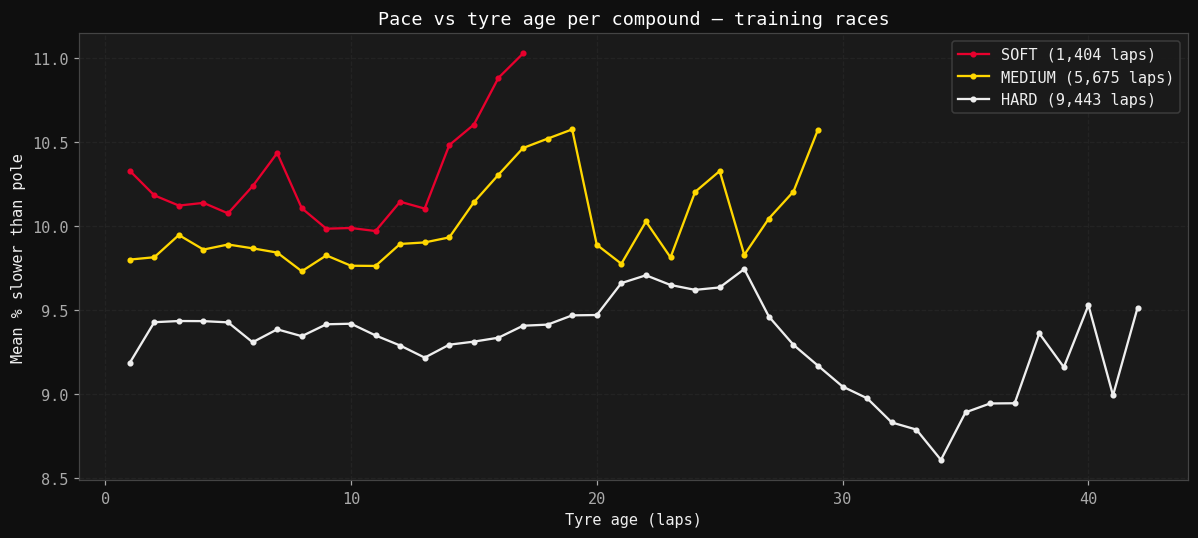

In [11]:
viz.plot_pace_vs_tyre_age(train, TARGET);

Softs and mediums lose pace as they age (tyre wear). Hards stay flat and even get faster late
in a stint. Hards are usually run in the second half of the race, when the car is lighter on fuel,
so the fuel effect hides the tyre wear. This is why the model gets `race_progress` (lap number /
race length, a proxy for fuel load) next to `tyre_age`.

## 3. Model selection: race-grouped cross-validation

Five folds over the training races; each fold holds out whole races. Two baselines set the bar:
- **Season average**: always predict the mean pace of the training laps.
- **Team average**: predict the team's mean pace (faster teams are closer to pole).

Two feature sets are compared: tyres + race state, and the same plus weather (track/air temperature,
humidity, rain).

In [12]:
trainer = F1ModelTrainer(FEATURE_SETS)
cv = trainer.cross_validate(train)
cv

,feature_set,model,cv_MAE_pct,cv_MAE_std,train_MAE_pct
0,tyres + race state,Linear (Ridge),1.810,0.220,1.679
1,tyres + race state,Gradient Boosting,1.872,0.158,1.434
2,tyres + race state,Random Forest,1.895,0.164,1.256
3,tyres + race state + weather,Linear (Ridge),1.947,0.323,1.516
4,tyres + race state,Baseline: team average,2.098,0.134,1.995
5,tyres + race state + weather,Baseline: team average,2.098,0.134,1.995
6,tyres + race state,Baseline: season average,2.185,0.144,2.096
7,tyres + race state + weather,Baseline: season average,2.185,0.144,2.096
8,tyres + race state + weather,Gradient Boosting,2.495,0.322,0.778
9,tyres + race state + weather,Random Forest,2.571,0.408,0.658


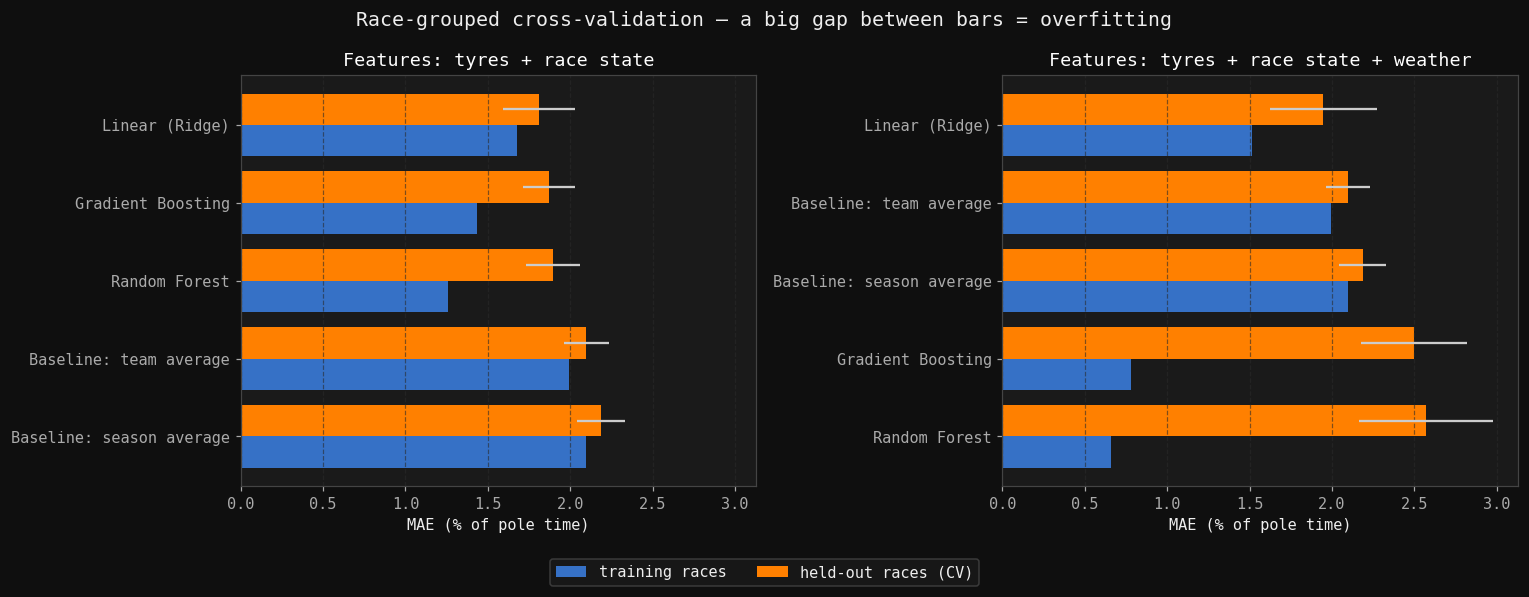

In [13]:
viz.plot_cv_results(cv);

**Findings**
- With tyre and race-state features, all three models beat both baselines. The linear model is best
  (1.81% vs 2.10% for the team average).
- **Adding weather makes the tree models much worse** (training error 0.7%, held-out error 2.5%).
  Each race has its own temperature and humidity, so the trees use them to *recognise the track*
  and memorise its pace. That doesn't transfer to a new track. Without race-grouped validation
  this would have looked like the best model.
- The selected model is **Ridge with tyres + race state**. It's chosen before looking at the
  test races.

In [14]:
best = cv[~cv["model"].str.startswith("Baseline")].iloc[0]
print(f"Selected: {best.model} — features: {best.feature_set}")

Selected: Linear (Ridge) — features: tyres + race state


## 4. Final evaluation on the test races (rounds 19–24)

All models are refit on all training races and scored once on the test races. The other models
are shown for context only; the selection above was already made.

In [15]:
trainer.evaluate_on_test(train, test, best.feature_set)
trainer.get_leaderboard()

,Model,MAE_pct,RMSE_pct,R2,MAE_s
0,Random Forest,1.601,2.075,-0.340,1.354
1,Gradient Boosting,1.613,2.013,-0.262,1.367
2,Linear (Ridge),1.641,2.107,-0.382,1.387
3,Baseline: team average,2.040,2.465,-0.892,1.735
4,Baseline: season average,2.114,2.581,-1.073,1.796


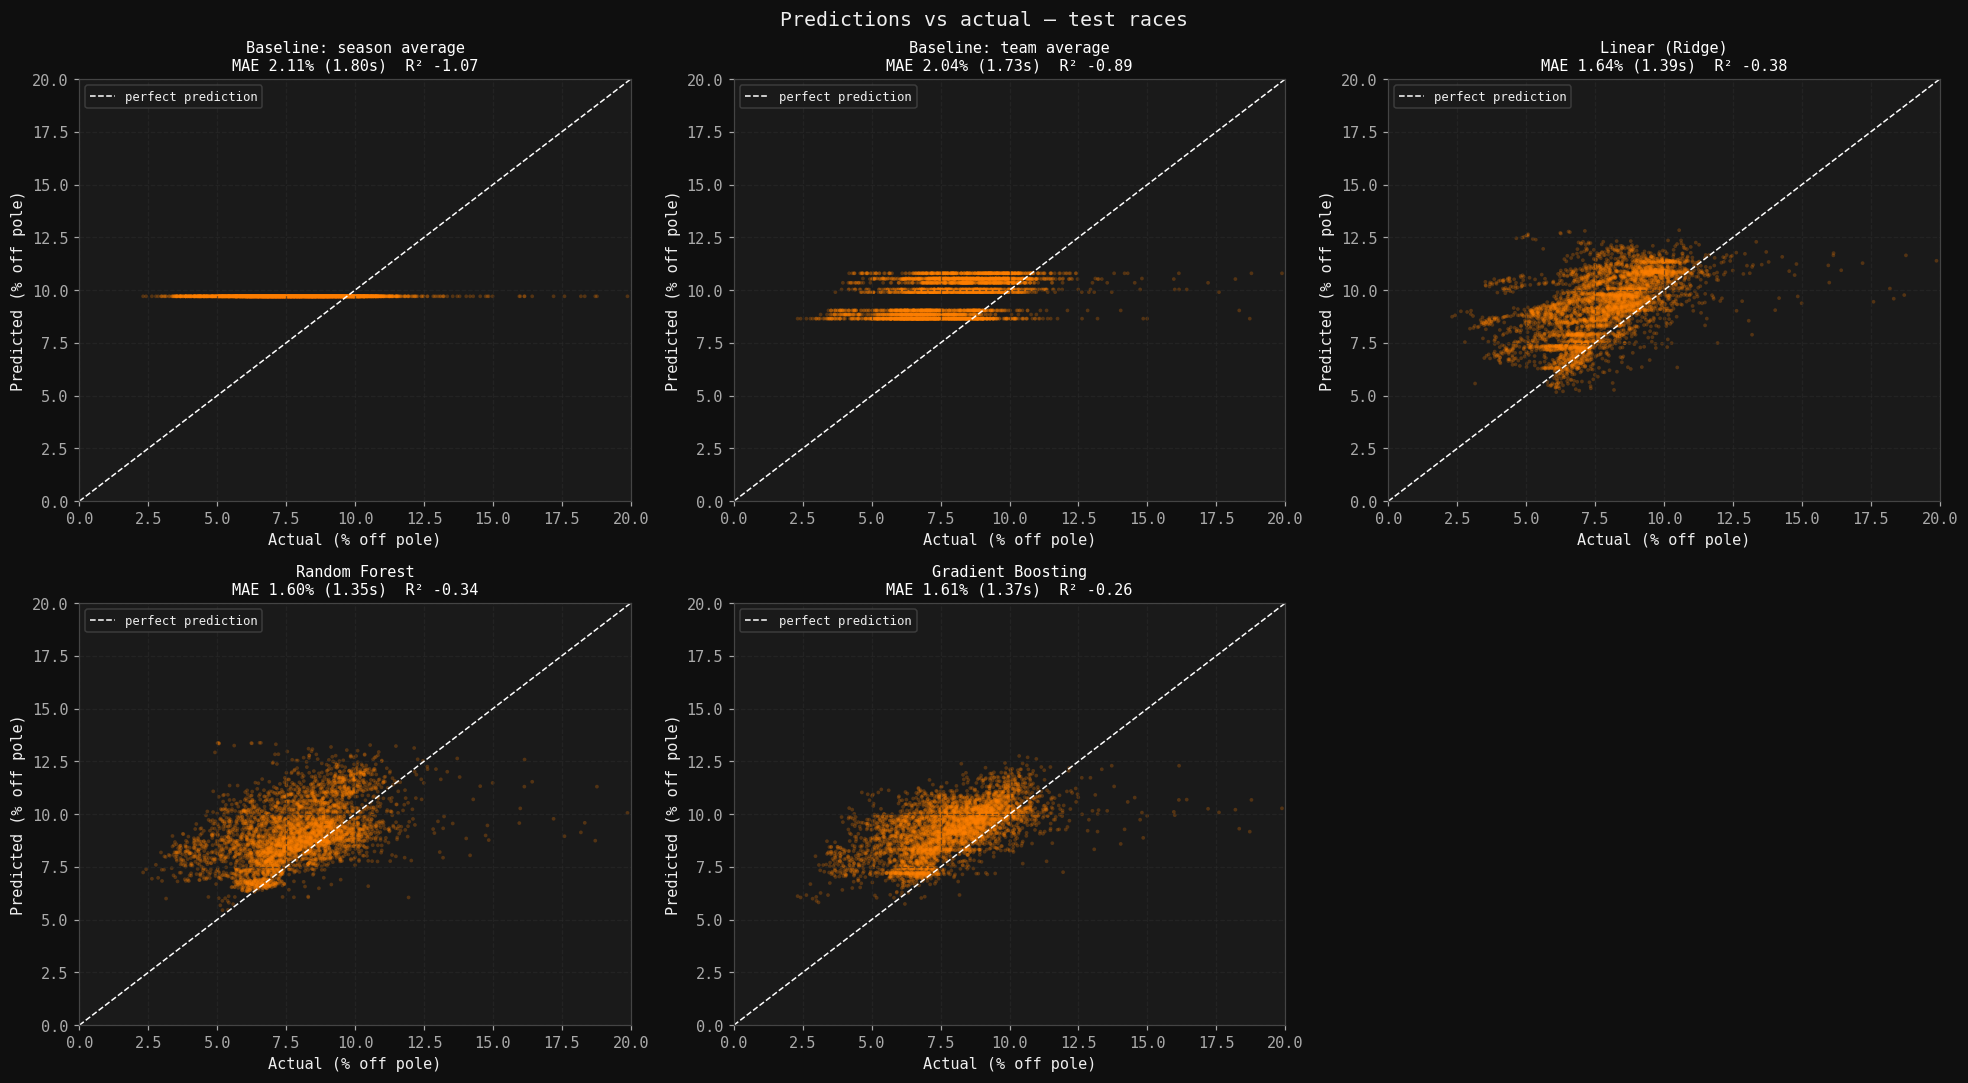

In [16]:
viz.plot_predictions_vs_actual(trainer.results);

The selected model's error is **1.64% of the pole time, about 1.4 s per lap**, vs 2.04%
(1.7 s) for the best baseline: **20% lower**. Random Forest and Gradient Boosting do about as well
on the test races (1.60–1.61%), in line with cross-validation where all three were close.

R² is negative for every model, including the baselines. R² compares against the *test set's own*
mean, which no model can know in advance, and the test races were on average faster relative to
pole (about 7.8%) than the training races (9.7%). MAE in seconds is the more meaningful metric here.

## 5. Error analysis

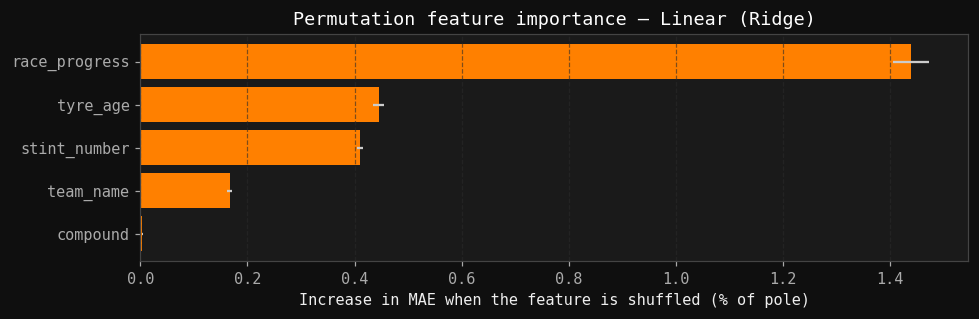

In [17]:
importance = trainer.get_feature_importance(best.model, test)
viz.plot_feature_importances(importance, best.model);

`race_progress` matters most: lap times fall steadily as fuel burns off. Then come tyre age and
stint. Compound adds little once the others are known.

,location,MAE_pct,bias_pct,laps
0,Lusail,3.225,3.088,721
1,Las Vegas,2.467,2.407,840
2,Yas Island,1.157,0.903,929
3,Mexico City,1.114,0.881,1063
4,Austin,0.759,0.230,936


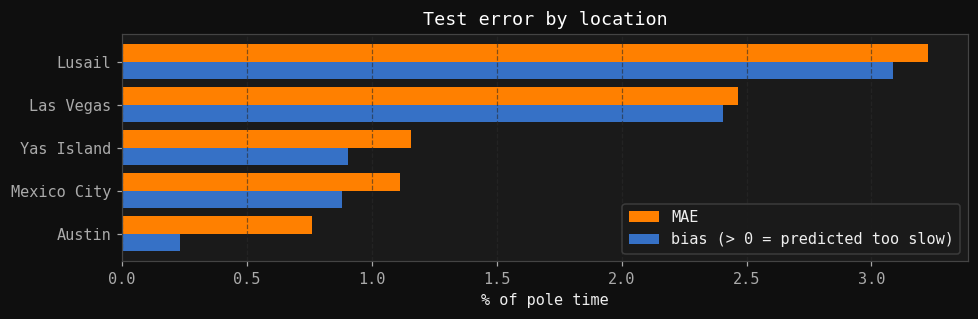

In [18]:
by_race = trainer.error_by_group(best.model, test, "location")
viz.plot_error_by_group(by_race, "location")
by_race

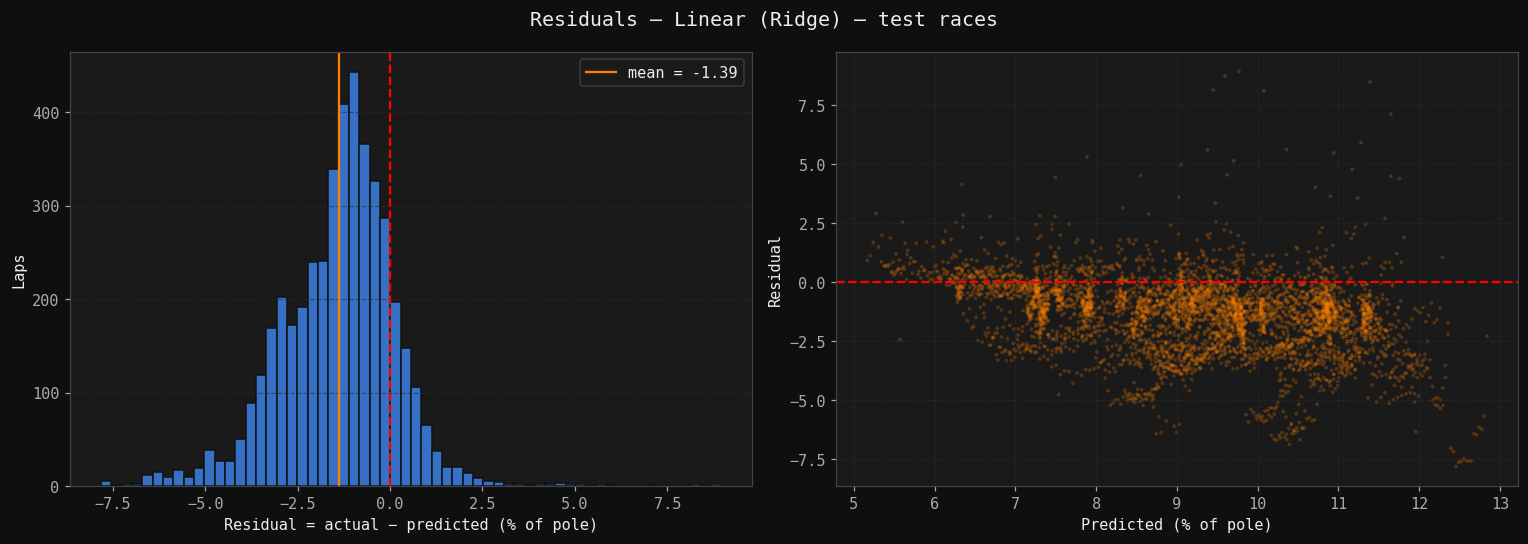

In [19]:
viz.plot_residuals(trainer.results, best.model);

The errors are mostly a **per-track bias, not random noise**. In every test race the model
predicts laps too slow. At Lusail and Las Vegas it is off by 2.4–3.1 points, while Austin is
nearly unbiased. Both tracks had race pace unusually close to pole (about 7%, among the lowest of
the season). The model has no information about the track, so it can't anticipate this.

## 6. Conclusions and limitations

**What works**
- A simple linear model using tyre and race-progress features predicts race lap times on unseen
  tracks to within about 1.4 s per lap, 20% better than the best baseline.
- Race-grouped validation was essential: it showed that weather features, which look helpful,
  actually make the tree models memorise tracks.

**Limitations**
- **Track effect:** most of the remaining error is how far race pace sits from pole at each track,
  which these features can't capture.
- **One season, 17 training tracks:** small sample for learning anything track-related; the test
  set is only 5 races, so its scores are noisy (cross-validation std ≈ 0.2 points).
- **Cleaning choices:** the 20% cut-off for safety-car laps is a rule of thumb, and laps run
  partly under a safety car can slip through. Traffic (being stuck behind a slower car) is not
  modelled.
- **Missing information:** fuel load and car setup are not public; `race_progress` is only a proxy.

**Next steps**
1. Add each track's race pace from the previous season as a feature. This targets the biggest
   source of error directly.
2. Add track characteristics (length, number of corners, share of time at full throttle from
   telemetry, as computed in section 1).
3. Add the gap to the car ahead to capture traffic.
4. Train on several seasons and evaluate season by season.